# 02 - ECAPA-TDNN Speaker Embeddings

## Objective

Extract a global speaker identity representation from VoxCeleb utterances using a pretrained ECAPA-TDNN model.

For an audio utterance $X$, we define:

$$
Z_{\mathrm{id}}(X)=E_{\mathrm{ECAPA}}(X).
$$

The ECAPA-TDNN encoder produces a 192-dimensional embedding representing speaker-related characteristics.

The first goal is to verify that the pretrained model can successfully produce an embedding for a single utterance.

We then evaluate whether the representation captures speaker identity by comparing cosine similarities between:

1. two utterances from the same speaker but different source videos;
2. two utterances from different speakers.

If the representation captures speaker identity, same-speaker similarities should be substantially larger than different-speaker similarities.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

print(Path.cwd())
print(PROJECT_ROOT)

/Users/juni/Documents/interview-anonymization/notebooks
/Users/juni/Documents/interview-anonymization


In [2]:
import random
from collections import defaultdict

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import soundfile as sf
import torch
from torch.nn.functional import cosine_similarity

from src.paths import (
    METADATA_DIR,
    PROCESSED_DATA_DIR,
    VOXCELEB_WAV_DIR,
)
from src.attacker_baseline.ecapa import load_ecapa, extract_embedding
from src.attacker_baseline.embedding_cache import SQLiteEmbeddingCache

CACHE_PATH = PROCESSED_DATA_DIR / "ecapa_embeddings.sqlite"
MODEL_ID = "speechbrain/spkrec-ecapa-voxceleb"

cache = SQLiteEmbeddingCache(
    db_path=CACHE_PATH,
    model_id=MODEL_ID,
)

def get_embedding_cached(audio_path: Path) -> torch.Tensor:
    """Return a cached ECAPA embedding or compute and cache it."""
    cached = cache.get(audio_path)

    if cached is not None:
        return torch.as_tensor(cached, dtype=torch.float32)

    embedding = extract_embedding(audio_path, classifier)
    cache.set(audio_path, embedding.numpy())

    return embedding


In [3]:
manifest_path = METADATA_DIR / "voxceleb_utterances.parquet"

utterance_df = pd.read_parquet(manifest_path)

# The manifest should contain paths relative to VOXCELEB_WAV_DIR.
wav_files = [
    VOXCELEB_WAV_DIR / Path(p)
    for p in utterance_df["path"]
]

if any(Path(p).is_absolute() for p in utterance_df["path"]):
    raise ValueError(
        "The manifest still contains absolute audio paths. "
        "Regenerate it by running notebook 1 first."
    )

if not all(p.is_file() for p in wav_files[:5]):
    raise FileNotFoundError(
        "Some audio files could not be found. Check VOXCELEB_WAV_DIR."
    )

print("Number of WAV files:", len(wav_files))
print("Sample:", wav_files[0])


Number of WAV files: 124843
Sample: /Users/juni/Documents/interview-anonymization/data/raw/voxceleb1/wav/id10001/1zcIwhmdeo4/00001.wav


In [4]:
sample_path = wav_files[0]
audio, sample_rate = sf.read(sample_path, dtype="float32")

if audio.ndim == 2:
    audio = audio.mean(axis=1)

waveform = torch.from_numpy(audio).unsqueeze(0)

print("Waveform shape:", waveform.shape)
print("Sample rate:", sample_rate)


Waveform shape: torch.Size([1, 129921])
Sample rate: 16000


In [5]:
duration = waveform.shape[1] / sample_rate
print(duration)

8.1200625


In [6]:
classifier = load_ecapa()

with torch.no_grad():
    embedding = classifier.encode_batch(waveform)

print("Embedding shape:", embedding.shape)

Embedding shape: torch.Size([1, 1, 192])


In [7]:
z_id = embedding.squeeze()

print("Z_id shape:", z_id.shape)
print(z_id[:10])

Z_id shape: torch.Size([192])
tensor([ 20.0208,  17.0411, -24.6932,  11.5568, -15.3953,  15.6592,  -2.7259,
        -36.5680,  17.8046,   4.0380])


In [8]:
speaker_a = wav_files[0].parts[-3]

speaker_files = [
    p for p in wav_files
    if p.parts[-3] == speaker_a
]

videos = sorted(set(p.parts[-2] for p in speaker_files))

video1, video2 = videos[:2]

path_a1 = next(p for p in speaker_files if p.parts[-2] == video1)
path_a2 = next(p for p in speaker_files if p.parts[-2] == video2)

In [9]:
path_b = next(
    p for p in wav_files
    if p.parts[-3] != speaker_a
)

In [10]:
z_a1 = get_embedding_cached(path_a1)
z_a2 = get_embedding_cached(path_a2)
z_b = get_embedding_cached(path_b)

In [11]:
sim_same = cosine_similarity(
    z_a1.unsqueeze(0),
    z_a2.unsqueeze(0)
).item()

sim_diff = cosine_similarity(
    z_a1.unsqueeze(0),
    z_b.unsqueeze(0)
).item()

print("Same speaker similarity:", sim_same)
print("Different speaker similarity:", sim_diff)

Same speaker similarity: 0.6504122018814087
Different speaker similarity: 0.04030593857169151


## ECAPA embedding validation

To verify that the ECAPA-TDNN embeddings capture speaker identity,
we compare cosine similarities between:

1. two utterances from the same speaker but different source videos;
2. two utterances from different speakers.

If the representation captures speaker identity, same-speaker
similarities should be substantially larger than different-speaker
similarities.

In [12]:
random.seed(42)

same_scores = []
diff_scores = []

# Index files once instead of scanning all paths in every trial.
files_by_speaker = defaultdict(list)
files_by_speaker_video = defaultdict(lambda: defaultdict(list))

for path in wav_files:
    speaker = path.parts[-3]
    video = path.parts[-2]

    files_by_speaker[speaker].append(path)
    files_by_speaker_video[speaker][video].append(path)

speakers = sorted(files_by_speaker)

# Only speakers with at least two videos can form a positive trial.
eligible_speakers = [
    speaker
    for speaker in speakers
    if len(files_by_speaker_video[speaker]) >= 2
]

if len(speakers) < 2 or not eligible_speakers:
    raise ValueError("Not enough speakers or videos for the evaluation.")

for _ in range(100):
    # Same speaker, different videos
    speaker = random.choice(eligible_speakers)
    videos = sorted(files_by_speaker_video[speaker])
    video1, video2 = random.sample(videos, 2)

    p1 = random.choice(files_by_speaker_video[speaker][video1])
    p2 = random.choice(files_by_speaker_video[speaker][video2])

    z1 = get_embedding_cached(p1)
    z2 = get_embedding_cached(p2)

    same_scores.append(
        cosine_similarity(z1.unsqueeze(0), z2.unsqueeze(0)).item()
    )

    # Different speakers
    speaker1, speaker2 = random.sample(speakers, 2)

    p1 = random.choice(files_by_speaker[speaker1])
    p2 = random.choice(files_by_speaker[speaker2])

    z1 = get_embedding_cached(p1)
    z2 = get_embedding_cached(p2)

    diff_scores.append(
        cosine_similarity(z1.unsqueeze(0), z2.unsqueeze(0)).item()
    )

print("Positive trials:", len(same_scores))
print("Negative trials:", len(diff_scores))
print("Cached embeddings:", len(cache))


Positive trials: 100
Negative trials: 100
Cached embeddings: 6401


In [13]:
print("Mean same-speaker similarity:", np.mean(same_scores))
print("Mean different-speaker similarity:", np.mean(diff_scores))

Mean same-speaker similarity: 0.6166029313206672
Mean different-speaker similarity: 0.005071844039484859


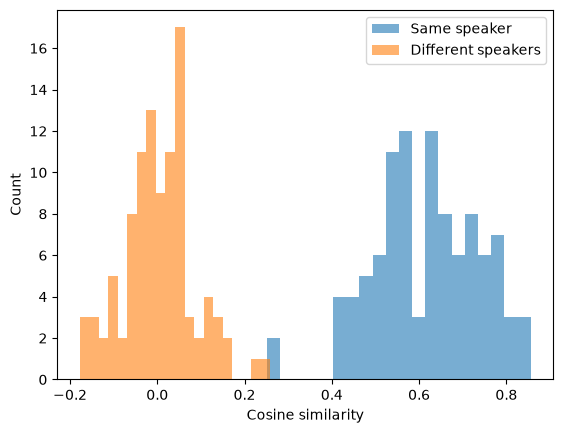

In [14]:
plt.hist(same_scores, bins=20, alpha=0.6, label="Same speaker")
plt.hist(diff_scores, bins=20, alpha=0.6, label="Different speakers")

plt.xlabel("Cosine similarity")
plt.ylabel("Count")
plt.legend()
plt.show()

In [15]:
same_series = pd.Series(same_scores, name="Same speaker")
diff_series = pd.Series(diff_scores, name="Different speakers")

print("Same speaker:")
print(same_series.describe())

print("\nDifferent speakers:")
print(diff_series.describe())

Same speaker:
count    100.000000
mean       0.616603
std        0.122378
min        0.251728
25%        0.542177
50%        0.622239
75%        0.715172
max        0.855600
Name: Same speaker, dtype: float64

Different speakers:
count    100.000000
mean       0.005072
std        0.081537
min       -0.177715
25%       -0.043878
50%       -0.001161
75%        0.050452
max        0.258946
Name: Different speakers, dtype: float64
